# LexisNexis Fraud Detection - Task 6: Model Comparison and Selection

Compares every model from Milestone 2 against each other and against a simple
lookup baseline, on the 1995 validation set, and selects one model to carry
into November.

The 1996 test year is **not opened in this notebook**. It stays sealed until
November, so the final number is produced once on data no decision was made
against.

All models use the 24 column feature list from Task 1, loaded from
`data/model_features.json`.

In [1]:
!rm -rf LexisNexis-1A-detecting-fraudulent-insurance-claims
!git clone -q https://github.com/Break-Through-Tech/LexisNexis-1A-detecting-fraudulent-insurance-claims.git
%cd /content/LexisNexis-1A-detecting-fraudulent-insurance-claims

/content/LexisNexis-1A-detecting-fraudulent-insurance-claims


In [2]:
import json
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score)

RANDOM_STATE = 42
CAPACITY = 0.20      # share of the claim book a review team can get through
N_BOOT = 1000        # bootstrap resamples

df = pd.read_csv("data/fraud_oracle_engineered.csv")

with open("data/model_features.json") as f:
    MODEL_FEATURES = json.load(f)

with open("data/m2_task4_5_tuned_params.json") as f:
    TUNED = json.load(f)

TARGET = "FraudFound_P"

train = df[df["Year"] == 1994].copy()
val   = df[df["Year"] == 1995].copy()
# 1996 is deliberately not loaded here.

X_train, y_train = train[MODEL_FEATURES], train[TARGET]
X_val,   y_val   = val[MODEL_FEATURES],   val[TARGET]

print("Features:", len(MODEL_FEATURES))
print("Train 1994:", X_train.shape, "fraud:", int(y_train.sum()))
print("Val   1995:", X_val.shape, "fraud:", int(y_val.sum()))
print("\nTuned settings loaded from Task 4/5:")
print(json.dumps(TUNED, indent=2))

Features: 24
Train 1994: (6141, 24) fraud: 409
Val   1995: (5195, 24) fraud: 301

Tuned settings loaded from Task 4/5:
{
  "logistic_regression": {
    "best_params": {
      "C": 0.008260808399079604
    },
    "cv_pr_auc_1994": 0.2033
  },
  "random_forest": {
    "best_params": {
      "max_depth": 20,
      "max_features": "sqrt",
      "min_samples_leaf": 10,
      "n_estimators": 500
    },
    "cv_pr_auc_1994": 0.2414
  },
  "gradient_boosting": {
    "best_params": {
      "l2_regularization": 0.1,
      "learning_rate": 0.029266761285490727,
      "max_depth": null,
      "max_features": 1.0,
      "max_iter": 100,
      "max_leaf_nodes": 15,
      "min_samples_leaf": 20
    },
    "cv_pr_auc_1994": 0.2638
  }
}


In [3]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()
grouped_categories = [c for c in ["Make", "PolicyType"]
                      if c in categorical_features]
regular_categories = [c for c in categorical_features
                      if c not in grouped_categories]


def make_preprocessor(dense=False):
    return ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())]), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))]),
         regular_categories),
        ("grouped_categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                     min_frequency=0.01))]), grouped_categories),
    ], sparse_threshold=0 if dense else 0.3)


def build_pipeline(model, dense=False):
    return Pipeline([("prep", make_preprocessor(dense)), ("clf", model)])


# Scores are ranked with a random tiebreak. This matters for the lookup
# baseline, which produces only six distinct scores across 5,195 claims.
_tie = np.random.default_rng(0)


def rank_order(proba):
    return np.lexsort((_tie.random(len(proba)), -np.asarray(proba)))


def evaluate_scores(name, proba, y_ev):
    proba = np.asarray(proba, dtype=float)
    y_arr = y_ev.to_numpy()
    n = len(proba)
    order = rank_order(proba)

    # Capacity means "review the top N claims", not "everything above score X".
    # Using a score threshold breaks on the lookup table, where six distinct
    # scores mean a single tie can drag in 44% of the book instead of 20%.
    # Ranking flags exactly the same number of claims for every model, which
    # is the only way the comparison is fair.
    k_cap = int(n * CAPACITY)
    pred_cap = np.zeros(n, dtype=int)
    pred_cap[order[:k_cap]] = 1

    pred_half = (proba >= 0.5).astype(int)

    y_sorted = y_arr[order]
    cap10 = y_sorted[:int(n * 0.10)].sum() / y_sorted.sum()
    cap20 = y_sorted[:int(n * 0.20)].sum() / y_sorted.sum()

    return {
        "Approach": name,
        "PR-AUC": average_precision_score(y_arr, proba),
        "Caught top 10%": cap10,
        "Caught top 20%": cap20,
        "Claims flagged": int(pred_cap.sum()),
        "Precision @cap": precision_score(y_arr, pred_cap, zero_division=0),
        "Recall @cap": recall_score(y_arr, pred_cap),
        "F1 @cap": f1_score(y_arr, pred_cap),
        "Precision @0.5": precision_score(y_arr, pred_half, zero_division=0),
        "Recall @0.5": recall_score(y_arr, pred_half),
        "F1 @0.5": f1_score(y_arr, pred_half),
    }


def evaluate_model(name, model, X_tr, y_tr, X_ev, y_ev):
    model.fit(X_tr, y_tr)
    proba = model.predict_proba(X_ev)[:, 1]
    return evaluate_scores(name, proba, y_ev), proba


print("Grouped:", grouped_categories)
print("Encoded columns:",
      make_preprocessor().fit(X_train).transform(X_train).shape[1])

Grouped: ['Make']
Encoded columns: 88


## The simple baseline

Our Challenge Advisor asked for a comparison point between "random guessing"
and a trained model. Using 1994 only, work out the fraud rate for each
combination of coverage type (`BasePolicy`) and who was at fault (`Fault`).
Then give every 1995 claim the rate for its group as its score.

That is the entire model: a six row lookup table, no training, no features
beyond two columns. It is surprisingly hard to beat, and if our models cannot
clearly clear it then that is something we need to know before November rather
than during the presentation.

In [4]:
lookup = (train.groupby(["BasePolicy", "Fault"])[TARGET]
               .agg(claims="count", fraud="sum", rate="mean")
               .reset_index()
               .sort_values("rate", ascending=False))

print("Fraud rate by BasePolicy and Fault, learned from 1994 only:\n")
display(lookup.round(4))

scored = val[["BasePolicy", "Fault"]].merge(
    lookup[["BasePolicy", "Fault", "rate"]],
    on=["BasePolicy", "Fault"], how="left")

unseen = int(scored["rate"].isna().sum())
lookup_proba = scored["rate"].fillna(y_train.mean()).to_numpy()

print(f"\n1995 claims scored: {len(lookup_proba):,}")
print(f"Combinations not present in 1994: {unseen} "
      f"(these get the overall 1994 fraud rate)")
print(f"Distinct scores the lookup can produce: "
      f"{len(np.unique(lookup_proba))}")

results, probas = [], {}
row = evaluate_scores("Lookup table (BasePolicy x Fault)", lookup_proba, y_val)
results.append(row)
probas["Lookup table (BasePolicy x Fault)"] = lookup_proba

display(pd.DataFrame([row]).set_index("Approach")
        [["PR-AUC", "Caught top 10%", "Caught top 20%"]].round(4))

Fraud rate by BasePolicy and Fault, learned from 1994 only:



,BasePolicy,Fault,claims,fraud,rate
0,All Perils,Policy Holder,1161,226,0.1947
2,Collision,Policy Holder,1681,152,0.0904
3,Collision,Third Party,712,11,0.0154
4,Liability,Policy Holder,1665,14,0.0084
1,All Perils,Third Party,653,5,0.0077
5,Liability,Third Party,269,1,0.0037



1995 claims scored: 5,195
Combinations not present in 1994: 0 (these get the overall 1994 fraud rate)
Distinct scores the lookup can produce: 6


,PR-AUC,Caught top 10%,Caught top 20%
Approach,,,
Lookup table (BasePolicy x Fault),0.1289,0.2359,0.4917


## Every model, scored on 1995

Each model is rebuilt here rather than loaded, so the whole comparison comes
from one run on one feature set. Tuned settings are read from
`data/m2_task4_5_tuned_params.json` so they stay in step with Task 4/5.

Training is 1994 only. Scoring is 1995 only. 1996 is not touched.

In [5]:
# If this cell is re-run on its own, drop everything except the lookup row
# so the table does not end up with duplicates.
results = [r for r in results if r["Approach"].startswith("Lookup")]
probas = {k: v for k, v in probas.items() if k.startswith("Lookup")}

lr_p = TUNED["logistic_regression"]["best_params"]
rf_p = TUNED["random_forest"]["best_params"]
gb_p = TUNED["gradient_boosting"]["best_params"]

candidates = {
    "LR, no handling": build_pipeline(
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "LR, class weighted": build_pipeline(
        LogisticRegression(class_weight="balanced", max_iter=1000,
                           random_state=RANDOM_STATE)),
    "LR, tuned": build_pipeline(
        LogisticRegression(class_weight="balanced", max_iter=2000,
                           random_state=RANDOM_STATE, **lr_p)),
    "RF, fully grown": build_pipeline(
        RandomForestClassifier(n_estimators=500, class_weight="balanced",
                               random_state=RANDOM_STATE, n_jobs=-1)),
    "RF, tuned": build_pipeline(
        RandomForestClassifier(class_weight="balanced",
                               random_state=RANDOM_STATE, n_jobs=-1, **rf_p)),
    "GB, default": build_pipeline(
        HistGradientBoostingClassifier(class_weight="balanced",
                                       random_state=RANDOM_STATE), dense=True),
    "GB, tuned": build_pipeline(
        HistGradientBoostingClassifier(class_weight="balanced",
                                       early_stopping=False,
                                       random_state=RANDOM_STATE, **gb_p),
        dense=True),
}

for name, model in candidates.items():
    row, proba = evaluate_model(name, model, X_train, y_train, X_val, y_val)
    results.append(row)
    probas[name] = proba
    print(f"done: {name}")

results_df = pd.DataFrame(results).set_index("Approach").round(4)
print("\nModels scored:", len(results_df))

done: LR, no handling
done: LR, class weighted
done: LR, tuned
done: RF, fully grown
done: RF, tuned
done: GB, default
done: GB, tuned

Models scored: 8


In [6]:
BASELINE = "Lookup table (BasePolicy x Fault)"

print("RANKING QUALITY, sorted by PR-AUC.")
print("Everything is measured against the lookup table, not against random.\n")
rank = results_df[["PR-AUC", "Caught top 10%", "Caught top 20%"]] \
    .sort_values("PR-AUC", ascending=False)
rank["PR-AUC vs lookup"] = (rank["PR-AUC"]
                            - results_df.loc[BASELINE, "PR-AUC"]).round(4)
rank["Top 10% vs lookup"] = (rank["Caught top 10%"]
                             - results_df.loc[BASELINE, "Caught top 10%"]).round(4)
rank["Top 20% vs lookup"] = (rank["Caught top 20%"]
                             - results_df.loc[BASELINE, "Caught top 20%"]).round(4)
display(rank)

print(f"\n\nAT A CUTOFF THAT FLAGS THE TOP {int(CAPACITY*100)}% OF CLAIMS.")
print("This is how any of these would actually be used.")
print("Every row should flag the same number of claims, otherwise the")
print("comparison is not fair.\n")
display(results_df[["Claims flagged", "Precision @cap", "Recall @cap",
                    "F1 @cap"]]
        .sort_values("F1 @cap", ascending=False))

base_rate = y_val.mean()
print(f"\nFor reference: the 1995 fraud rate is {base_rate:.4f}, which is also "
      f"the PR-AUC a random ranking would score.")
print("Reviewing a random 20% of claims would catch 20% of the fraud.")

RANKING QUALITY, sorted by PR-AUC.
Everything is measured against the lookup table, not against random.



,PR-AUC,Caught top 10%,Caught top 20%,PR-AUC vs lookup,Top 10% vs lookup,Top 20% vs lookup
Approach,,,,,,
"GB, tuned",0.1901,0.2857,0.5116,0.0612,0.0498,0.0199
"GB, default",0.1770,0.2791,0.4751,0.0481,0.0432,-0.0166
"RF, fully grown",0.1556,0.3223,0.5382,0.0267,0.0864,0.0465
"LR, no handling",0.1488,0.2824,0.5216,0.0199,0.0465,0.0299
"RF, tuned",0.1463,0.2791,0.5150,0.0174,0.0432,0.0233
"LR, class weighted",0.1393,0.2724,0.5083,0.0104,0.0365,0.0166
"LR, tuned",0.1317,0.2791,0.4784,0.0028,0.0432,-0.0133
Lookup table (BasePolicy x Fault),0.1289,0.2359,0.4917,0.0000,0.0000,0.0000




AT A CUTOFF THAT FLAGS THE TOP 20% OF CLAIMS.
This is how any of these would actually be used.
Every row should flag the same number of claims, otherwise the
comparison is not fair.



,Claims flagged,Precision @cap,Recall @cap,F1 @cap
Approach,,,,
"RF, fully grown",1039,0.1559,0.5382,0.2418
"LR, no handling",1039,0.1511,0.5216,0.2343
"RF, tuned",1039,0.1492,0.5150,0.2313
"GB, tuned",1039,0.1482,0.5116,0.2299
"LR, class weighted",1039,0.1473,0.5083,0.2284
Lookup table (BasePolicy x Fault),1039,0.1424,0.4917,0.2209
"LR, tuned",1039,0.1386,0.4784,0.2149
"GB, default",1039,0.1376,0.4751,0.2134



For reference: the 1995 fraud rate is 0.0579, which is also the PR-AUC a random ranking would score.
Reviewing a random 20% of claims would catch 20% of the fraud.


## Are any of these differences real?

1995 holds 301 fraud cases, which is not many, so every number above carries
noise. This resamples the 1995 claims 1,000 times and recomputes both metrics
on each resample, which gives a range rather than a single figure.

Everything is compared against the lookup table rather than against random
guessing, because clearing the lookup is the bar that actually matters. A
model that cannot clearly beat six rows of arithmetic is not earning its
complexity.

Both metrics get tested, because they disagree about which model is best and
we cannot pick whichever one flatters our preferred answer.

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
y_val_arr = y_val.to_numpy()
n = len(y_val_arr)
boot_idx = rng.integers(0, n, size=(N_BOOT, n))
k10, k20 = int(n * 0.10), int(n * 0.20)


def boot_metrics(proba):
    """PR-AUC and capture at 10% and 20% across every bootstrap resample."""
    proba = np.asarray(proba, dtype=float)
    pr = np.empty(N_BOOT)
    c10 = np.empty(N_BOOT)
    c20 = np.empty(N_BOOT)
    tie = np.random.default_rng(1)
    for j, i in enumerate(boot_idx):
        yb, pb = y_val_arr[i], proba[i]
        pr[j] = average_precision_score(yb, pb)
        order = np.lexsort((tie.random(len(pb)), -pb))
        total = yb.sum()
        c10[j] = yb[order[:k10]].sum() / total
        c20[j] = yb[order[:k20]].sum() / total
    return pr, c10, c20


print(f"Resampling 1995 {N_BOOT} times for {len(probas)} models, "
      f"this takes a minute...\n")
boot_pr, boot_c10, boot_c20 = {}, {}, {}
for name, p in probas.items():
    boot_pr[name], boot_c10[name], boot_c20[name] = boot_metrics(p)
    print(f"  done: {name}")

rows = []
for name in probas:
    is_base = name == BASELINE
    dp = boot_pr[name] - boot_pr[BASELINE]
    d10 = boot_c10[name] - boot_c10[BASELINE]
    d20 = boot_c20[name] - boot_c20[BASELINE]
    rows.append({
        "Approach": name,
        "PR-AUC": results_df.loc[name, "PR-AUC"],
        "PR diff low": np.nan if is_base else np.percentile(dp, 2.5),
        "PR diff high": np.nan if is_base else np.percentile(dp, 97.5),
        "PR beats lookup": np.nan if is_base else (dp > 0).mean(),
        "Top10": results_df.loc[name, "Caught top 10%"],
        "T10 diff low": np.nan if is_base else np.percentile(d10, 2.5),
        "T10 diff high": np.nan if is_base else np.percentile(d10, 97.5),
        "T10 beats lookup": np.nan if is_base else (d10 > 0).mean(),
        "Top20": results_df.loc[name, "Caught top 20%"],
        "T20 diff low": np.nan if is_base else np.percentile(d20, 2.5),
        "T20 diff high": np.nan if is_base else np.percentile(d20, 97.5),
        "T20 beats lookup": np.nan if is_base else (d20 > 0).mean(),
    })

boot_df = pd.DataFrame(rows).set_index("Approach").round(4)

print("\n\nPR-AUC against the lookup table.")
print("A model clears the bar only if 'diff low' is above 0.\n")
display(boot_df[["PR-AUC", "PR diff low", "PR diff high", "PR beats lookup"]]
        .sort_values("PR-AUC", ascending=False))

print("\n\nTOP 10% CAPTURE against the lookup table.")
print("This is the tightest review capacity, where the lookup is weakest")
print("because it cannot rank claims inside a group.\n")
display(boot_df[["Top10", "T10 diff low", "T10 diff high", "T10 beats lookup"]]
        .sort_values("Top10", ascending=False))

print("\n\nTOP 20% CAPTURE against the lookup table.\n")
display(boot_df[["Top20", "T20 diff low", "T20 diff high", "T20 beats lookup"]]
        .sort_values("Top20", ascending=False))

# The two models Task 6 has to choose between
A, B = "GB, tuned", "RF, fully grown"
print(f"\n\nHEAD TO HEAD: {A} minus {B}")
for label, store, col in [("PR-AUC", boot_pr, "PR-AUC"),
                          ("top 10% capture", boot_c10, "Caught top 10%"),
                          ("top 20% capture", boot_c20, "Caught top 20%")]:
    d = store[A] - store[B]
    lo, hi = np.percentile(d, 2.5), np.percentile(d, 97.5)
    point = results_df.loc[A, col] - results_df.loc[B, col]
    print(f"\n  on {label}")
    print(f"    difference: {point:+.4f}")
    print(f"    95% range:  {lo:+.4f} to {hi:+.4f}")
    print(f"    {A} ahead in {(d > 0).mean():.1%} of resamples")
    print("    -> clear" if (lo > 0 or hi < 0)
          else "    -> NOT clear, the range includes 0")

Resampling 1995 1000 times for 8 models, this takes a minute...

  done: Lookup table (BasePolicy x Fault)
  done: LR, no handling
  done: LR, class weighted
  done: LR, tuned
  done: RF, fully grown
  done: RF, tuned
  done: GB, default
  done: GB, tuned


PR-AUC against the lookup table.
A model clears the bar only if 'diff low' is above 0.



,PR-AUC,PR diff low,PR diff high,PR beats lookup
Approach,,,,
"GB, tuned",0.1901,0.0321,0.0994,1.000
"GB, default",0.1770,0.0203,0.0883,0.999
"RF, fully grown",0.1556,0.0099,0.0523,1.000
"LR, no handling",0.1488,0.0056,0.0410,0.997
"RF, tuned",0.1463,0.0069,0.0337,0.999
"LR, class weighted",0.1393,-0.0034,0.0303,0.933
"LR, tuned",0.1317,-0.0062,0.0159,0.763
Lookup table (BasePolicy x Fault),0.1289,NaN,NaN,NaN




TOP 10% CAPTURE against the lookup table.
This is the tightest review capacity, where the lookup is weakest
because it cannot rank claims inside a group.



,Top10,T10 diff low,T10 diff high,T10 beats lookup
Approach,,,,
"RF, fully grown",0.3223,0.0111,0.1230,0.987
"GB, tuned",0.2857,-0.0212,0.0877,0.871
"LR, no handling",0.2824,-0.0257,0.0839,0.826
"LR, tuned",0.2791,-0.0342,0.0780,0.783
"RF, tuned",0.2791,-0.0266,0.0733,0.813
"GB, default",0.2791,-0.0329,0.0797,0.754
"LR, class weighted",0.2724,-0.0414,0.0747,0.698
Lookup table (BasePolicy x Fault),0.2359,NaN,NaN,NaN




TOP 20% CAPTURE against the lookup table.



,Top20,T20 diff low,T20 diff high,T20 beats lookup
Approach,,,,
"RF, fully grown",0.5382,-0.0134,0.1001,0.925
"LR, no handling",0.5216,-0.0228,0.0805,0.843
"RF, tuned",0.5150,-0.0228,0.0708,0.807
"GB, tuned",0.5116,-0.0292,0.0698,0.783
"LR, class weighted",0.5083,-0.0393,0.0747,0.691
Lookup table (BasePolicy x Fault),0.4917,NaN,NaN,NaN
"LR, tuned",0.4784,-0.0580,0.0431,0.334
"GB, default",0.4751,-0.0825,0.0451,0.276




HEAD TO HEAD: GB, tuned minus RF, fully grown

  on PR-AUC
    difference: +0.0345
    95% range:  +0.0057 to +0.0633
    GB, tuned ahead in 98.7% of resamples
    -> clear

  on top 10% capture
    difference: -0.0366
    95% range:  -0.0836 to +0.0129
    GB, tuned ahead in 8.2% of resamples
    -> NOT clear, the range includes 0

  on top 20% capture
    difference: -0.0266
    95% range:  -0.0727 to +0.0249
    GB, tuned ahead in 16.7% of resamples
    -> NOT clear, the range includes 0


## Evidence for dropping the month columns

Our Challenge Advisor asked for a chart of fraud cases per month per year.
noticed that :  fraud nearly disappears during certain blocks of months, and those blocks shift between years.

If the shift is real, the month columns are not just weak features, they are
actively misleading, because the pattern a model learns from one year is the
wrong pattern for the next.

Fraud cases by month and year:



Month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Year,,,,,,,,,,,,
1994,48,36,56,47,52,47,32,56,9,1,8,17
1995,39,45,45,10,1,1,0,1,39,50,26,44
1996,0,1,1,23,41,32,28,27,28,19,12,1


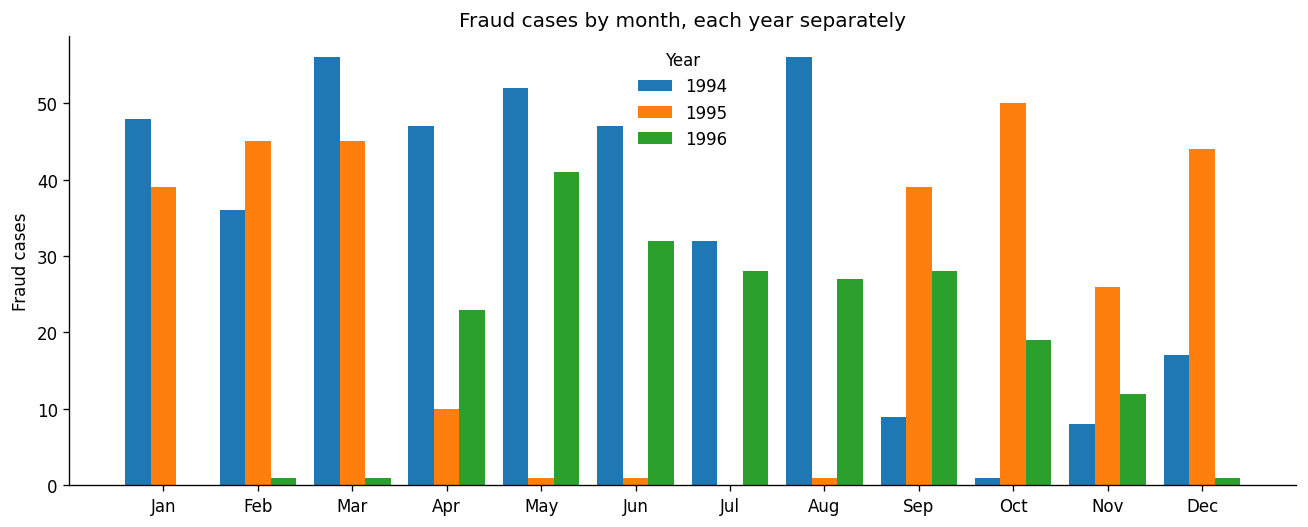


Quietest and busiest month in each year:
  1994: lowest Oct (1 cases), highest Mar (56 cases)
  1995: lowest Jul (0 cases), highest Oct (50 cases)
  1996: lowest Jan (0 cases), highest May (41 cases)


In [8]:
import matplotlib.pyplot as plt

MONTH_ORDER = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

counts = (df.groupby(["Year", "Month"])[TARGET].sum()
            .unstack("Month")
            .reindex(columns=MONTH_ORDER)
            .fillna(0)
            .astype(int))

print("Fraud cases by month and year:\n")
display(counts)

fig, ax = plt.subplots(figsize=(11, 4.5), dpi=120)
x = np.arange(12)
width = 0.27
for k, yr in enumerate([1994, 1995, 1996]):
    ax.bar(x + (k - 1) * width, counts.loc[yr], width, label=str(yr))

ax.set_xticks(x)
ax.set_xticklabels(MONTH_ORDER)
ax.set_ylabel("Fraud cases")
ax.set_title("Fraud cases by month, each year separately")
ax.legend(title="Year", frameon=False)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

print("\nQuietest and busiest month in each year:")
for yr in [1994, 1995, 1996]:
    r = counts.loc[yr]
    print(f"  {yr}: lowest {r.idxmin()} ({r.min()} cases), "
          f"highest {r.idxmax()} ({r.max()} cases)")

### What the chart shows

**October 1994 has 1 fraud case. October 1995 has 50.** Same month, consecutive
years, the emptiest month of one year and the busiest month of the next.

Laid end to end as one timeline, the near-empty stretches are:

- September to December 1994
- April to August 1995
- January to March 1996
- December 1996

Those stretches do not line up with each other and they do not repeat on any
annual cycle. A real seasonal effect in insurance fraud would land in roughly
the same months every year.

The likelier explanation is that these are periods when the insurer's fraud
unit was not resolving or recording cases, and the claims filed during them sit
in the data labeled not-fraud by default. That makes `Month` and `MonthClaimed`
a record of the insurer's internal operations rather than anything about the
claims, which is exactly the kind of column that works beautifully in training
and fails in production.

**Two consequences:**

1. Both month columns stay out of the feature list. Confirmed by our ablation
   test, by Stephanie's feature importance review, and by Keyah's own rerun.
2. The target column itself is imperfect. Some share of the claims labeled 0 in
   those stretches are probably fraud that was never investigated, which means
   every score in this project is measured against a label that undercounts
   fraud. This is worth raising with the host company, and it is a limitation
   we should state in the final presentation rather than let someone find.

## Model selection

Three measures, each tested against the lookup table with 1,000 bootstrap
resamples of the 1995 claims. A model only clears the bar if the bottom of
its 95% range sits above zero.

| | PR-AUC | Top 10% | Top 20% |
|---|---|---|---|
| **RF, fully grown** | **clears** | **clears** | no |
| GB, tuned | clears | no | no |
| GB, default | clears | no | no |
| LR, no handling | clears | no | no |
| RF, tuned | clears | no | no |
| LR, class weighted | no | no | no |
| LR, tuned | no | no | no |

**Selected model: the fully grown random forest.**
`RandomForestClassifier(n_estimators=500, class_weight="balanced")`, with no
depth or leaf size limit, on the 24 column feature list.

It is the only model in the project with a demonstrated advantage over the
lookup table at a review capacity anyone would actually use, and it clears the
baseline on PR-AUC as well. Tuned gradient boosting has a genuinely better
PR-AUC, +0.0345 against the forest with a 95% range of +0.0057 to +0.0633, but
that advantage does not appear at either operating point. It orders the whole
book better without putting more fraud at the top of it.

### Recommended review capacity: the top 10%

At 10% the forest catches 32.2% of fraud against the lookup's 23.6%, which is
roughly 26 extra fraud cases out of 301, and that gap holds up in 98.7% of
resamples. At 20% it catches 53.8% against 49.2%, about 14 extra cases, and
that gap does not hold up.

Stated honestly: reviewing 20% still catches more fraud in total, so a team
with that capacity should use it. But the model is worth roughly twice as much
per claim reviewed at 10%, and 10% is the only capacity where we can show it
is worth having at all.

### What this says about the month of the project

The feature work mattered more than the modelling. Removing Month and
MonthClaimed moved PR-AUC from 0.1002 to 0.1488, about +0.049. Moving from
logistic regression to the fully grown forest moved it from 0.1488 to 0.1556,
about +0.007. The features were worth roughly seven times the model upgrade.

In [9]:
final_table = results_df.join(
    boot_df[["PR diff low", "PR diff high", "PR beats lookup",
             "T10 diff low", "T10 diff high", "T10 beats lookup",
             "T20 diff low", "T20 diff high", "T20 beats lookup"]])

final_table.round(4).to_csv("data/m2_task6_model_comparison.csv")

decision = {
    "selected_model": "RandomForestClassifier, fully grown",
    "settings": {"n_estimators": 500, "class_weight": "balanced",
                 "max_depth": None, "min_samples_leaf": 1},
    "feature_list": "data/model_features.json (24 columns)",
    "recommended_review_capacity": 0.10,
    "validation_1995": {
        "pr_auc": float(results_df.loc["RF, fully grown", "PR-AUC"]),
        "caught_top_10": float(results_df.loc["RF, fully grown", "Caught top 10%"]),
        "caught_top_20": float(results_df.loc["RF, fully grown", "Caught top 20%"]),
    },
    "lookup_baseline_1995": {
        "pr_auc": float(results_df.loc[BASELINE, "PR-AUC"]),
        "caught_top_10": float(results_df.loc[BASELINE, "Caught top 10%"]),
        "caught_top_20": float(results_df.loc[BASELINE, "Caught top 20%"]),
    },
    "test_year_status": "1996 not opened. Reserved for a single November run.",
}

with open("data/m2_task6_decision.json", "w") as f:
    json.dump(decision, f, indent=2)

print("Saved data/m2_task6_model_comparison.csv")
print("Saved data/m2_task6_decision.json\n")
print(json.dumps(decision, indent=2))

Saved data/m2_task6_model_comparison.csv
Saved data/m2_task6_decision.json

{
  "selected_model": "RandomForestClassifier, fully grown",
  "settings": {
    "n_estimators": 500,
    "class_weight": "balanced",
    "max_depth": null,
    "min_samples_leaf": 1
  },
  "feature_list": "data/model_features.json (24 columns)",
  "recommended_review_capacity": 0.1,
  "validation_1995": {
    "pr_auc": 0.1556,
    "caught_top_10": 0.3223,
    "caught_top_20": 0.5382
  },
  "lookup_baseline_1995": {
    "pr_auc": 0.1289,
    "caught_top_10": 0.2359,
    "caught_top_20": 0.4917
  },
  "test_year_status": "1996 not opened. Reserved for a single November run."
}


## Limitations

Four things a reader should know before trusting the number above.

**One validation year.** Every conclusion here rests on 5,195 claims from
1995. The bootstrap intervals measure how much those 5,195 claims could have
varied by chance, but they cannot measure whether 1995 itself was a normal
year. With three years of data and one of them sealed, there is no way around
this.

**The labels undercount fraud.** For the reason shown in the month chart
above, some claims labeled not-fraud were probably never investigated. Every
score in this notebook is measured against that, so our real recall is likely
lower than reported and our real precision is likely higher.

**Three features are excluded on an argument we could not confirm.**
`PoliceReportFiled`, `WitnessPresent` and `AddressChange_Claim` were dropped
because we could not tell from the data whether they are recorded at intake
or added during an investigation. If the host company confirms they are
recorded at intake, all three go back in and the results change.

**The margin over the baseline is small.** The selected model catches 32.2%
of fraud in the top 10% against the lookup table's 23.6%. On 1995 that is
about 26 extra fraud cases out of 301. It is a real improvement and it holds
up under resampling, but it is not the kind of gap that makes the choice
obvious, and the maintenance cost of a random forest against a six-row table
is a fair thing for the host company to weigh.